In [12]:
import h5py
import pandas as pd
import plotly.express as px
import numpy as np
import matplotlib.pyplot as plt

# for a given matrix type and a given implementation, plot boxplots of the componentwise relative errors for each dimension
def plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_gt_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == gt_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_relative_errors
    # note the potential divide-by-zero issue here
    dims = []
    unsigned_relative_errors = []
    for mat_id, gt_mat_id in zip(filtered_ids, filtered_gt_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        gt_mat = matrices_dict[f"{gt_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        gt_vals = gt_mat.flatten()
        unsigned_relative_errors.append(abs((vals - gt_vals) / gt_vals))
    
    # plot
    ax.boxplot(unsigned_relative_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}, {input_type} matrices")
    ax.set_yscale("log")

In [7]:
h5_file = h5py.File("grading_dgemm.h5", "r")

matrices_dict = h5_file["matrices"]

metadata_df = pd.DataFrame(h5_file["metadata"][:])
metadata_df["matrix_name"] = metadata_df["matrix_name"].str.decode("utf-8")
metadata_df["input_type"] = metadata_df["input_type"].str.decode("utf-8")
metadata_df["matrix_name"].unique()

array(['A', 'B', 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-13.0-unknown-unknown-NVCC8.0',
       'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3',
       'REFERENCE_1-649b52d-GNU_13.2-O0-x86_64_zen3',
       'CUBLAS_eager_strat-13.0-unknown-unknown-NVCC8.0',
       'CUBLAS_no_emulation-13.0-unknown-unknown-NVCC8.0',
       'CUBLAS_fixed_mantissa_55-13.0-unknown-unknown-NVCC8.0',
       'CUBLAS_fixed_mantissa_23-13.0-unknown-unknown-NVCC8.0',
       'REFERENCE_1_EXTENDED_PRECISION-unknown-GNU_13.2-O0-x86_64_zen3'],
      dtype=object)

# U(0,1) w/ naive $O(n^3)$ reference _in long double precision_

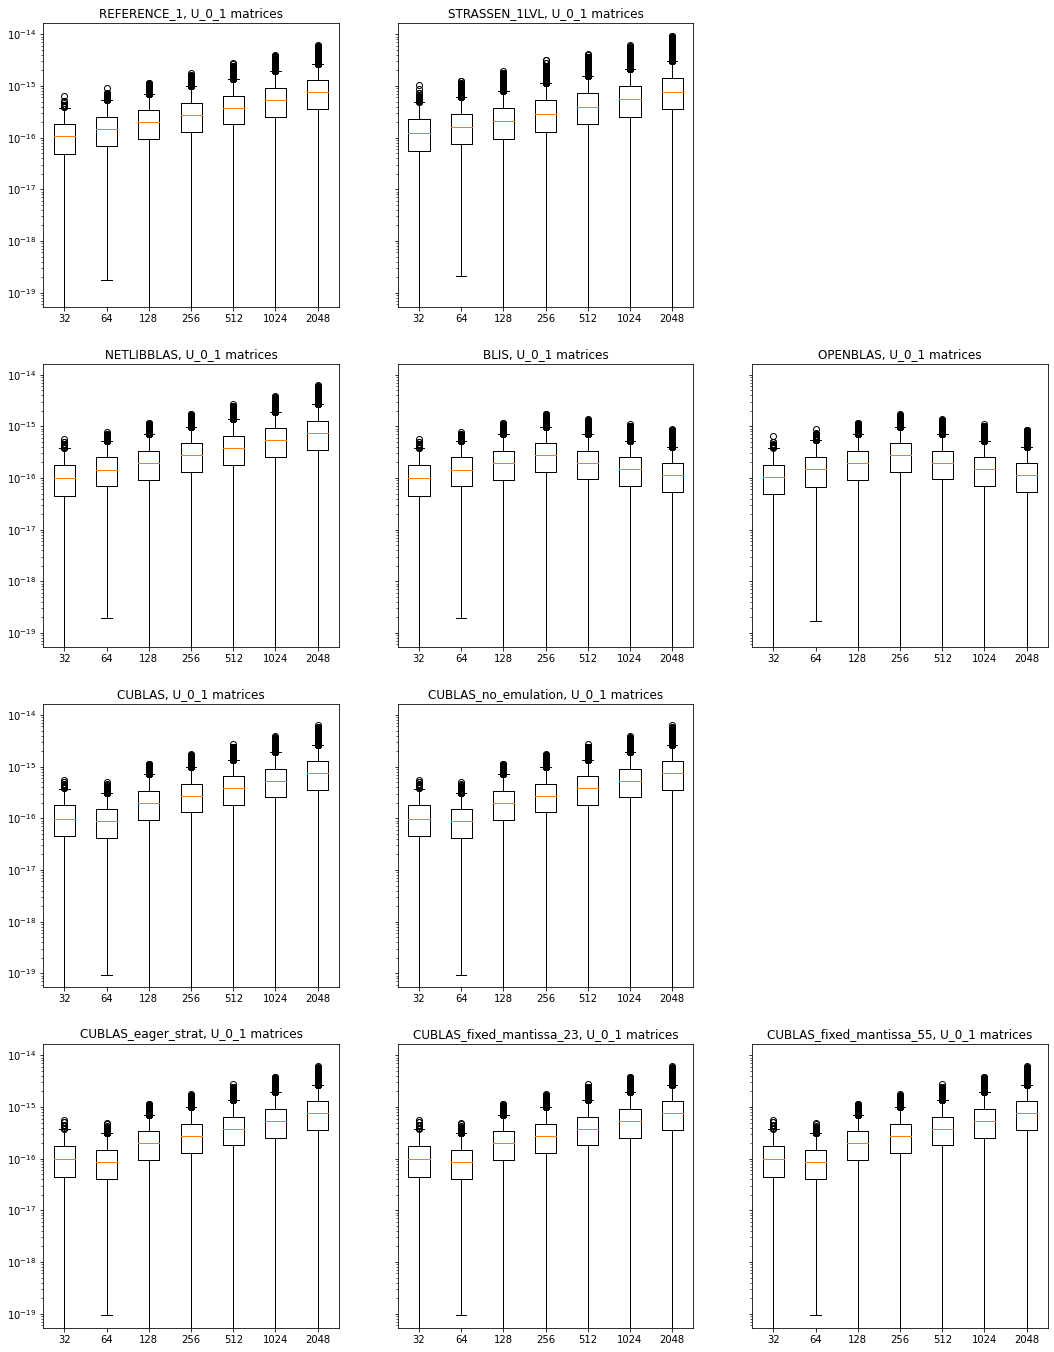

In [18]:
gt_impl = "REFERENCE_1_EXTENDED_PRECISION-unknown-GNU_13.2-O0-x86_64_zen3"
input_type = "U_0_1"

fig, axs = plt.subplots(4,3, figsize=(18,24), sharey=True)

subplot_tuples = [
        ( (0,0), 'REFERENCE_1-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (0,1), 'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (1,0), 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,1), 'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,2), 'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (2,0), 'CUBLAS-13.0-unknown-unknown-NVCC8.0'),
        ( (2,1), 'CUBLAS_no_emulation-13.0-unknown-unknown-NVCC8.0'),
        ( (3,0), 'CUBLAS_eager_strat-13.0-unknown-unknown-NVCC8.0'),
        ( (3,1), 'CUBLAS_fixed_mantissa_23-13.0-unknown-unknown-NVCC8.0'),
        ( (3,2), 'CUBLAS_fixed_mantissa_55-13.0-unknown-unknown-NVCC8.0'),
]

axs[0,2].remove()
axs[2,2].remove()

for subplot_pos, impl in subplot_tuples:
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_pos[0], subplot_pos[1]])

# U(0,1) w/ naive $O(n^3)$ reference in double precision

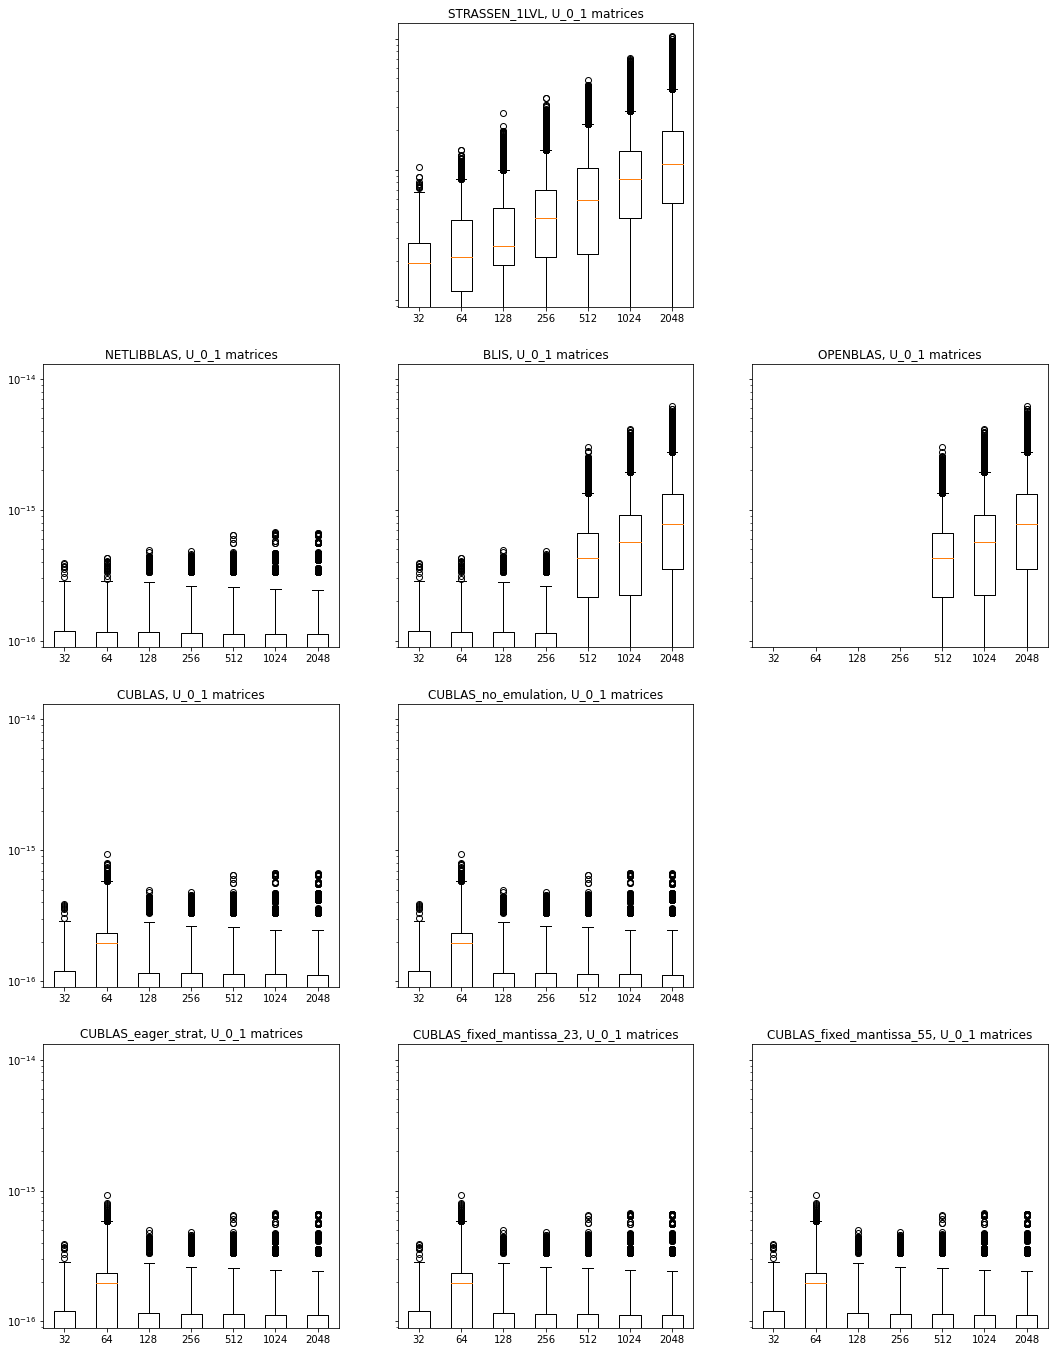

In [19]:
gt_impl = "REFERENCE_1-649b52d-GNU_13.2-O0-x86_64_zen3"
input_type = "U_0_1"

fig, axs = plt.subplots(4,3, figsize=(18,24), sharey=True)

subplot_tuples = [
        ( (0,1), 'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (1,0), 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,1), 'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,2), 'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (2,0), 'CUBLAS-13.0-unknown-unknown-NVCC8.0'),
        ( (2,1), 'CUBLAS_no_emulation-13.0-unknown-unknown-NVCC8.0'),
        ( (3,0), 'CUBLAS_eager_strat-13.0-unknown-unknown-NVCC8.0'),
        ( (3,1), 'CUBLAS_fixed_mantissa_23-13.0-unknown-unknown-NVCC8.0'),
        ( (3,2), 'CUBLAS_fixed_mantissa_55-13.0-unknown-unknown-NVCC8.0'),
]

axs[0,0].remove()
axs[0,2].remove()
axs[2,2].remove()

for subplot_pos, impl in subplot_tuples:
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_pos[0], subplot_pos[1]])

# U(-1,1) w/ naive $O(n^3)$ reference in _long double precision_

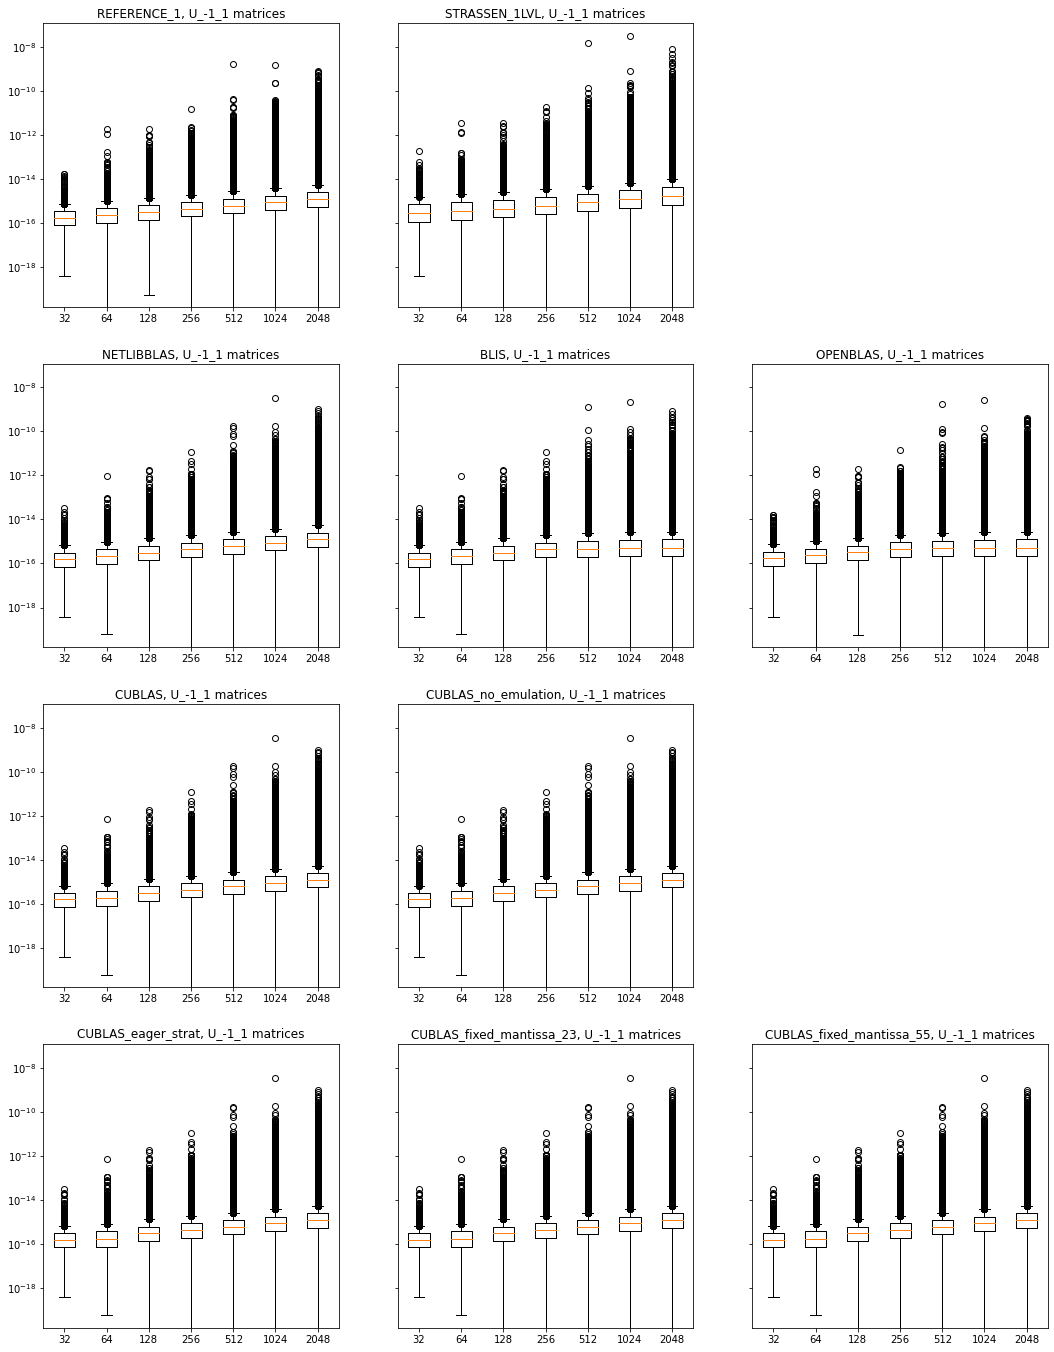

In [15]:
gt_impl = "REFERENCE_1_EXTENDED_PRECISION-unknown-GNU_13.2-O0-x86_64_zen3"
input_type = "U_-1_1"

fig, axs = plt.subplots(4,3, figsize=(18,24), sharey=True)

subplot_tuples = [
        ( (0,0), 'REFERENCE_1-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (0,1), 'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (1,0), 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,1), 'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,2), 'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (2,0), 'CUBLAS-13.0-unknown-unknown-NVCC8.0'),
        ( (2,1), 'CUBLAS_no_emulation-13.0-unknown-unknown-NVCC8.0'),
        ( (3,0), 'CUBLAS_eager_strat-13.0-unknown-unknown-NVCC8.0'),
        ( (3,1), 'CUBLAS_fixed_mantissa_23-13.0-unknown-unknown-NVCC8.0'),
        ( (3,2), 'CUBLAS_fixed_mantissa_55-13.0-unknown-unknown-NVCC8.0'),
]

axs[0,2].remove()
axs[2,2].remove()

for subplot_pos, impl in subplot_tuples:
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_pos[0], subplot_pos[1]])

# U(-1,1) w/ naive $O(n^3)$ reference in double precision

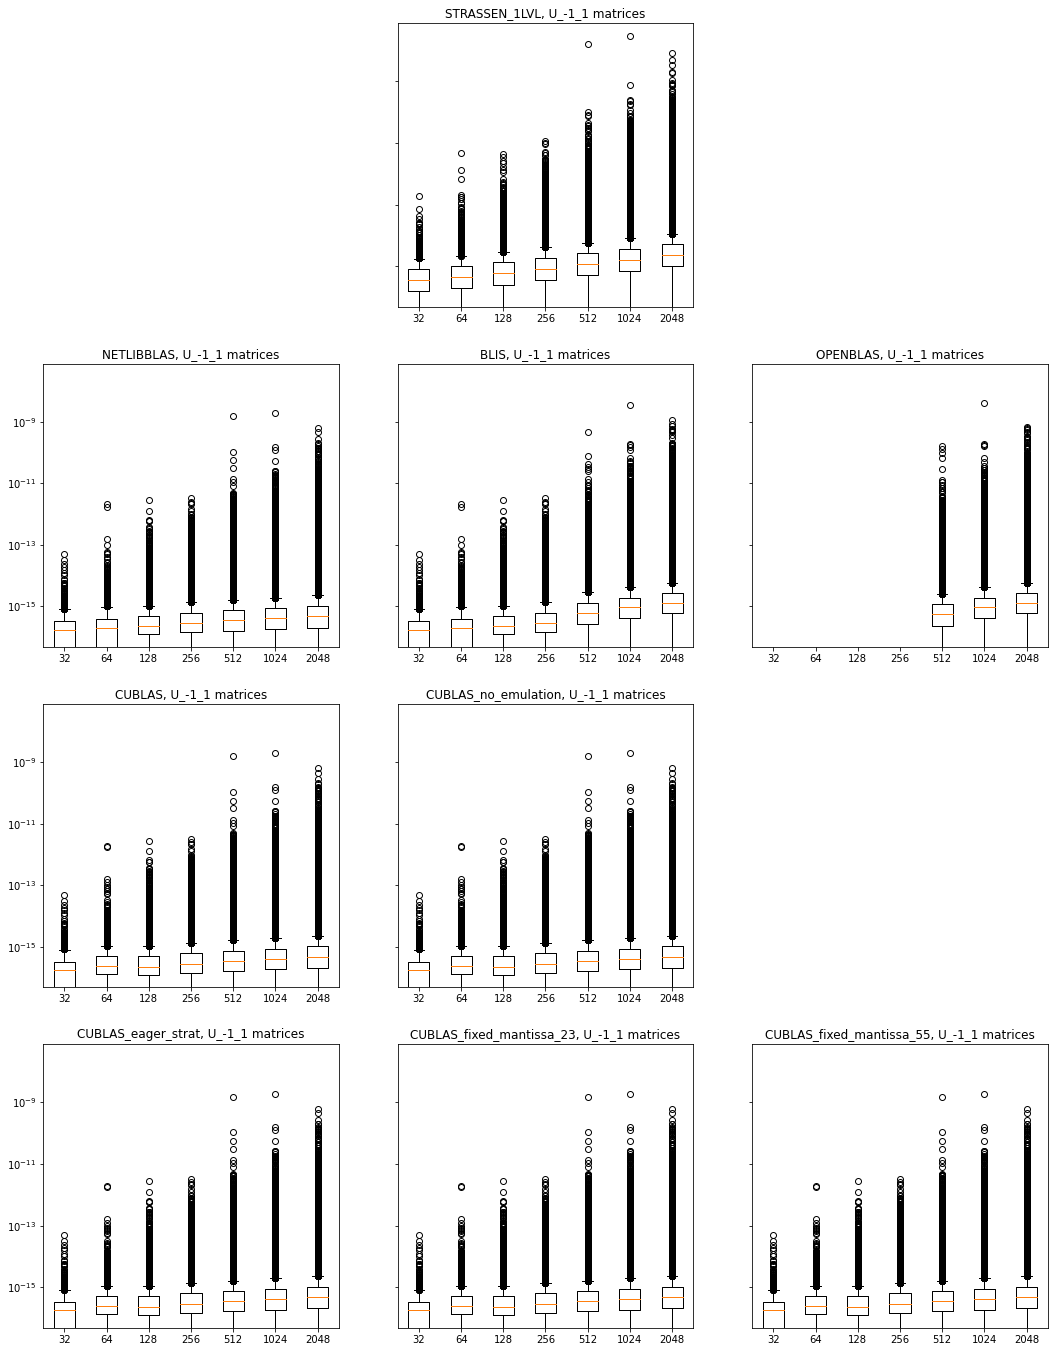

In [16]:
gt_impl = "REFERENCE_1-649b52d-GNU_13.2-O0-x86_64_zen3"
input_type = "U_-1_1"

fig, axs = plt.subplots(4,3, figsize=(18,24), sharey=True)

subplot_tuples = [
        ( (0,1), 'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (1,0), 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,1), 'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,2), 'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (2,0), 'CUBLAS-13.0-unknown-unknown-NVCC8.0'),
        ( (2,1), 'CUBLAS_no_emulation-13.0-unknown-unknown-NVCC8.0'),
        ( (3,0), 'CUBLAS_eager_strat-13.0-unknown-unknown-NVCC8.0'),
        ( (3,1), 'CUBLAS_fixed_mantissa_23-13.0-unknown-unknown-NVCC8.0'),
        ( (3,2), 'CUBLAS_fixed_mantissa_55-13.0-unknown-unknown-NVCC8.0'),
]

axs[0,0].remove()
axs[0,2].remove()
axs[2,2].remove()

for subplot_pos, impl in subplot_tuples:
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_pos[0], subplot_pos[1]])

# Test3 w/ naive $O(n^3)$ reference in _long double precision_

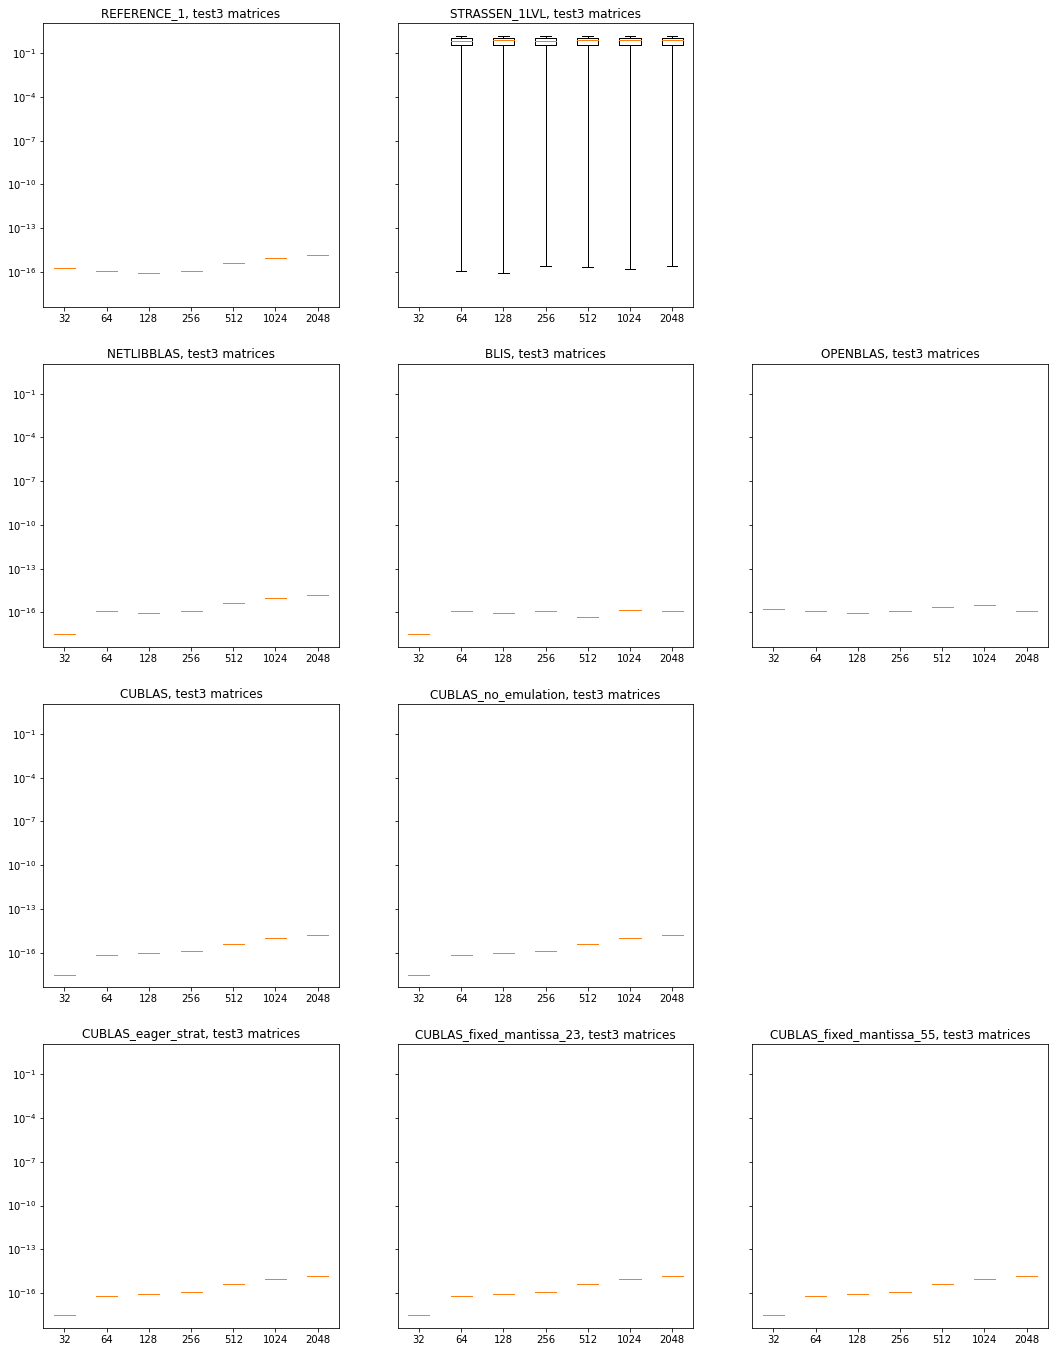

In [17]:
gt_impl = "REFERENCE_1_EXTENDED_PRECISION-unknown-GNU_13.2-O0-x86_64_zen3"
input_type = "test3"

fig, axs = plt.subplots(4,3, figsize=(18,24), sharey=True)

subplot_tuples = [
        ( (0,0), 'REFERENCE_1-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (0,1), 'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3'),
        ( (1,0), 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,1), 'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (1,2), 'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3'),
        ( (2,0), 'CUBLAS-13.0-unknown-unknown-NVCC8.0'),
        ( (2,1), 'CUBLAS_no_emulation-13.0-unknown-unknown-NVCC8.0'),
        ( (3,0), 'CUBLAS_eager_strat-13.0-unknown-unknown-NVCC8.0'),
        ( (3,1), 'CUBLAS_fixed_mantissa_23-13.0-unknown-unknown-NVCC8.0'),
        ( (3,2), 'CUBLAS_fixed_mantissa_55-13.0-unknown-unknown-NVCC8.0'),
]
# U(0,1) w/ naive $O(n^3)$ reference in double precision
axs[0,2].remove()
axs[2,2].remove()

for subplot_pos, impl in subplot_tuples:
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_pos[0], subplot_pos[1]])